# Teste A/B — Electronic House: Preenchimento Manual vs. Automático no Checkout

## 1. Contexto de Negócio e Objetivo
A **Electronic House** é um *e-commerce* global de produtos de informática presente na América Latina, América do Norte e Europa. Para reduzir o atrito na finalização da compra e funcionar de forma consistente em todos os países, o time de Engenharia desenvolveu um novo checkout em que **90% dos dados do cartão de crédito são preenchidos automaticamente**.

Este estudo avalia com rigor estatístico os resultados do experimento controlado conduzido na página de vendas para responder à pergunta central:
> **Qual a melhor forma de pagamento: Preenchimento Manual (`GRP B`) ou Preenchimento Automático (`GRP A`) do formulário de cartão de crédito?**

### Dicionário Experimental e Hipóteses Estatísticas
- **Grupo Tratamento (`GRP A` — Preenchimento Automático):** Novo fluxo em que 90% dos dados do cartão são preenchidos automaticamente.
- **Grupo Controle (`GRP B` — Preenchimento Manual):** Fluxo tradicional de digitação manual de todas as informações do cartão.
- **Canais / Dispositivos (`device`):**
  - `I` = Compra realizada através do **Site** (Web).
  - `A` = Compra realizada através do **App** (Aplicativo).
- **Hipótese Nula ($H_0$):** Não há diferença estatisticamente significativa nas métricas de desempenho (gasto médio por cliente, volume de compras ou ticket médio) entre o Preenchimento Automático (`GRP A`) e o Preenchimento Manual (`GRP B`), isto é, $\mu_A = \mu_B$.
- **Hipótese Alternativa ($H_1$):** Existe diferença estatisticamente significativa nas métricas de desempenho entre `GRP A` e `GRP B` ($\mu_A \neq \mu_B$).
- **Nível de Significância ($\alpha$):** $0{,}05$ (confiança de $95\%$) e Poder Estatístico ($1 - \beta$) de $80\%$.

---

## 2. Carregamento dos Dados e Inspeção de Schema

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

warnings.filterwarnings('ignore', category=FutureWarning)
sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 110

PALETTE = {
    'GRP B (Manual)': '#2B5C8F',
    'GRP A (Automático)': '#E07A5F',
}

df = pd.read_csv('ab_testing.csv')

print(f'Dimensões do dataset: {df.shape[0]:,} linhas x {df.shape[1]} colunas\n')
print('Tipos de dados por coluna:')
print(df.dtypes)
display(df.head(10))

Dimensões do dataset: 45,883 linhas x 8 colunas

Tipos de dados por coluna:
uid           int64
country      object
gender       object
spent         int64
purchases     int64
date         object
group        object
device       object
dtype: object


,uid,country,gender,spent,purchases,date,group,device
0,11115722,MEX,F,1595,5,2016-03-08,GRP B,I
1,11122053,USA,M,498,2,2017-07-14,GRP B,I
2,11128688,USA,F,2394,6,2017-09-17,GRP A,I
3,11130578,USA,F,1197,3,2017-11-30,GRP A,I
4,11130759,ESP,M,1297,3,2018-01-10,GRP B,A
5,11131070,USA,M,1796,4,2016-08-08,GRP B,I
6,11131381,GBR,F,2296,4,2017-05-21,GRP B,A
7,11131664,TUR,M,2293,7,2017-12-20,GRP B,I
8,11132813,USA,M,698,2,2017-07-27,GRP A,I
9,11134390,DEU,F,498,2,2017-11-16,GRP B,I


### Análise da Estrutura Inicial
A base `ab_testing.csv` reúne os registros ao nível de cliente (`uid`), associando cada usuário ao grupo experimental visualizado (`GRP A` = Preenchimento Automático; `GRP B` = Preenchimento Manual), país (`country`), gênero (`gender`), canal/dispositivo da compra (`device`: `I` = Site; `A` = App), data do registro (`date`), número de compras efetuadas (`purchases`) e valor total gasto (`spent`).

Antes de qualquer inferência estatística, verificamos a integridade dos dados: presença de valores nulos, duplicidade de usuários (ou contaminação de um mesmo `uid` nos dois grupos simultaneamente) e consistência numérica das variáveis de receita e volume de compras.

---

## 3. Auditoria de Qualidade e Preparação dos Dados

In [2]:
# 1. Verificação de valores nulos / ausentes
missing_summary = pd.DataFrame({
    'nulos': df.isna().sum(),
    'percentual (%)': (df.isna().mean() * 100).round(4)
})
print('--- Valores Ausentes por Coluna ---')
display(missing_summary)

# 2. Verificação de duplicatas e contaminação entre grupos
dup_rows = df.duplicated().sum()
dup_uids = df['uid'].duplicated().sum()
cross_group_uids = (df.groupby('uid')['group'].nunique() > 1).sum()

# 3. Verificação de consistência de valores numéricos
invalid_spent = (df['spent'] < 0).sum()
invalid_purchases = (df['purchases'] < 0).sum()
zero_purchases = (df['purchases'] == 0).sum()
inconsistent_zero = (((df['spent'] > 0) & (df['purchases'] == 0)) | ((df['spent'] == 0) & (df['purchases'] > 0))).sum()

print(f'Linhas inteiramente duplicadas: {dup_rows}')
print(f'UIDs duplicados: {dup_uids}')
print(f'UIDs presentes em ambos os grupos (contaminação A/B): {cross_group_uids}')
print(f'Registros com spent < 0: {invalid_spent} | purchases < 0: {invalid_purchases}')
print(f'Registros com purchases == 0 (não convertidos na base): {zero_purchases}')
print(f'Registros inconsistentes entre spent e purchases: {inconsistent_zero}\n')

# 4. Limpeza preservando todas as colunas originais
df_clean = df.copy()

if cross_group_uids > 0:
    contaminated_ids = df_clean.groupby('uid')['group'].nunique()
    contaminated_ids = contaminated_ids[contaminated_ids > 1].index
    df_clean = df_clean[~df_clean['uid'].isin(contaminated_ids)].copy()

df_clean = df_clean.dropna(subset=['group', 'spent', 'purchases']).copy()
for cat_col in ['country', 'gender', 'device']:
    if df_clean[cat_col].isna().any():
        df_clean[cat_col] = df_clean[cat_col].fillna('Unknown')

df_clean = df_clean[(df_clean['spent'] >= 0) & (df_clean['purchases'] >= 0)].copy()
df_clean['date'] = pd.to_datetime(df_clean['date'], errors='coerce')

group_map = {
    'GRP A': 'GRP A (Automático)',
    'GRP B': 'GRP B (Manual)',
}
device_map = {
    'I': 'I (Site)',
    'A': 'A (App)',
}
df_clean['group_label'] = df_clean['group'].map(group_map).fillna(df_clean['group'])
df_clean['device_label'] = df_clean['device'].map(device_map).fillna(df_clean['device'])
df_clean['converted'] = (df_clean['purchases'] > 0).astype(int)
df_clean['avg_ticket'] = np.where(
    df_clean['purchases'] > 0,
    df_clean['spent'] / df_clean['purchases'],
    0.0
)

print(f'Base final pronta para análise: {len(df_clean):,} registros')
print(f"Período do experimento: {df_clean['date'].min().date()} até {df_clean['date'].max().date()}")
print(f"Países presentes ({df_clean['country'].nunique()}): {sorted(df_clean['country'].unique())}")
print(f"Canais presentes: {sorted(df_clean['device_label'].unique())} | Gêneros: {sorted(df_clean['gender'].unique())}")

--- Valores Ausentes por Coluna ---


,nulos,percentual (%)
uid,0,0.0
country,0,0.0
gender,0,0.0
spent,0,0.0
purchases,0,0.0
date,0,0.0
group,0,0.0
device,0,0.0


Linhas inteiramente duplicadas: 0
UIDs duplicados: 0
UIDs presentes em ambos os grupos (contaminação A/B): 0
Registros com spent < 0: 0 | purchases < 0: 0
Registros com purchases == 0 (não convertidos na base): 0
Registros inconsistentes entre spent e purchases: 0

Base final pronta para análise: 45,883 registros
Período do experimento: 2014-01-30 até 2018-01-26
Países presentes (10): ['AUS', 'BRA', 'CAN', 'DEU', 'ESP', 'FRA', 'GBR', 'MEX', 'TUR', 'USA']
Canais presentes: ['A (App)', 'I (Site)'] | Gêneros: ['F', 'M']


### Análise da Qualidade e Definição das Métricas
A auditoria assegura que nenhum registro apresente valores negativos, contaminação de usuários entre grupos (`GRP A` e `GRP B`) ou perda de colunas originais. Caso a base contenha exclusivamente clientes que já finalizaram ao menos uma compra (`purchases >= 1`), a taxa de conversão binária dentro da amostra é de 100%, tornando o **Gasto Médio por Cliente (`spent` / ARPU)**, o **Número Médio de Compras (`purchases`)** e o **Ticket Médio por Compra (`avg_ticket`)** as métricas primárias para mensurar a efetividade comercial do preenchimento automático frente ao manual. Se houver registros com `purchases == 0`, a taxa de conversão (`converted`) também é avaliada diretamente.

---

## 4. Validação do Desenho Experimental (Poder Amostral, SRM e Homogeneidade)
Em um Teste A/B confiável, precisamos confirmar três pilares antes de comparar os resultados:
1. **Suficiência amostral (Power Analysis):** cada grupo possui clientes suficientes para detectar um efeito mínimo relevante (ex.: *lift* de 2% a 5% no gasto médio) com poder estatístico de 80% e $\alpha = 0{,}05$?
2. **Ausência de *Sample Ratio Mismatch* (SRM):** a divisão de tráfego entre `GRP A` e `GRP B` respeita a proporção esperada de 50%/50%?
3. **Equilíbrio de covariáveis:** a distribuição de países (`country`), dispositivos (`device`) e gêneros (`gender`) é homogênea entre os dois grupos?

In [3]:
grp_counts = df_clean['group_label'].value_counts()
n_a = int(grp_counts.get('GRP A (Automático)', 0))
n_b = int(grp_counts.get('GRP B (Manual)', 0))
n_total = n_a + n_b

# 1. Teste de Sample Ratio Mismatch (SRM) - proporção esperada 50/50
srm_stat, srm_pval = stats.chisquare(f_obs=[n_a, n_b], f_exp=[n_total / 2, n_total / 2])

# 2. Cálculo do Tamanho Mínimo de Amostra por Grupo (α = 0.05 bicaudal, Poder = 80%)
z_alpha = stats.norm.ppf(1 - 0.05 / 2)
z_beta = stats.norm.ppf(0.80)
baseline_mean = df_clean.loc[df_clean['group'] == 'GRP B', 'spent'].mean()  # Controle: GRP B (Manual)
pooled_std = df_clean['spent'].std(ddof=1)

for mde_pct in [0.05, 0.02]:
    delta = baseline_mean * mde_pct
    n_min = int(np.ceil(2 * (((z_alpha + z_beta) * pooled_std) / delta) ** 2))
    adequado = 'SIM' if min(n_a, n_b) >= n_min else 'NÃO'
    print(f'Tamanho mínimo por grupo para detectar lift de {mde_pct*100:.0f}% (Poder 80%, α=5%): {n_min:,} -> Atendido? {adequado}')

print(f'\nContagem por grupo: GRP A (Automático) = {n_a:,} ({n_a/n_total*100:.2f}%) | GRP B (Manual) = {n_b:,} ({n_b/n_total*100:.2f}%)')
print(f'Teste SRM (Qui-quadrado 50/50): estatística = {srm_stat:.4f}, p-valor = {srm_pval:.4f}\n')

# 3. Homogeneidade de covariáveis entre GRP A e GRP B
cov_results = []
for col in ['country', 'gender', 'device_label']:
    ct = pd.crosstab(df_clean['group_label'], df_clean[col])
    chi2, p_val, dof, _ = stats.chi2_contingency(ct)
    cov_results.append({
        'Variável': col,
        'Graus de Liberdade': dof,
        'Qui-Quadrado': round(chi2, 4),
        'p-valor': round(p_val, 4),
        'Grupos Balanceados (p >= 0.05)?': 'Sim' if p_val >= 0.05 else 'Atenção (p < 0.05)'
    })
print('--- Homogeneidade Demográfica e de Canal entre Grupos ---')
display(pd.DataFrame(cov_results))

# 4. Estatísticas Descritivas Globais por Grupo
desc_metrics = df_clean.groupby('group_label').agg(
    clientes=('uid', 'count'),
    receita_total=('spent', 'sum'),
    spent_media=('spent', 'mean'),
    spent_dp=('spent', 'std'),
    spent_mediana=('spent', 'median'),
    purchases_media=('purchases', 'mean'),
    purchases_mediana=('purchases', 'median'),
    ticket_medio_cliente=('avg_ticket', 'mean'),
    taxa_conversao=('converted', 'mean'),
).round(4)

print('--- Resumo Descritivo por Grupo ---')
display(desc_metrics)

Tamanho mínimo por grupo para detectar lift de 5% (Poder 80%, α=5%): 3,283 -> Atendido? SIM
Tamanho mínimo por grupo para detectar lift de 2% (Poder 80%, α=5%): 20,516 -> Atendido? SIM

Contagem por grupo: GRP A (Automático) = 23,009 (50.15%) | GRP B (Manual) = 22,874 (49.85%)
Teste SRM (Qui-quadrado 50/50): estatística = 0.3972, p-valor = 0.5285

--- Homogeneidade Demográfica e de Canal entre Grupos ---


,Variável,Graus de Liberdade,Qui-Quadrado,p-valor,Grupos Balanceados (p >= 0.05)?
0,country,9,24.4193,0.0037,Atenção (p < 0.05)
1,gender,1,0.7218,0.3956,Sim
2,device_label,1,0.4854,0.4860,Sim


--- Resumo Descritivo por Grupo ---


,clientes,receita_total,spent_media,spent_dp,spent_mediana,purchases_media,purchases_mediana,ticket_medio_cliente,taxa_conversao
group_label,,,,,,,,,
GRP A (Automático),23009,43268523,1880.5043,1368.4028,1596.0,4.5364,4.0,415.0673,1.0
GRP B (Manual),22874,43149967,1886.4198,1359.4224,1596.0,4.5525,4.0,415.0262,1.0


### Análise do Desenho Experimental e Estatísticas Descritivas
Os testes acima validam se a randomização do *Front-End* distribuiu os usuários de maneira equilibrada entre o Preenchimento Automático (`GRP A` — Tratamento) e o Preenchimento Manual (`GRP B` — Controle), além de comprovar que o tamanho amostral (~22,9 mil usuários por grupo) supera com ampla folga o mínimo exigido pelo cálculo de poder estatístico (mesmo para efeitos sutis de 2% no gasto médio).

Na tabela descritiva, comparamos simultaneamente medidas de tendência central paramétricas (média e desvio-padrão) e robustas (mediana) para `spent`, `purchases` e `avg_ticket`. A seguir, inspecionamos visualmente a forma das distribuições e a presença de *outliers* para embasar a escolha dos testes de hipóteses.

---

## 5. Análise Visual das Distribuições (`spent` e `purchases`)

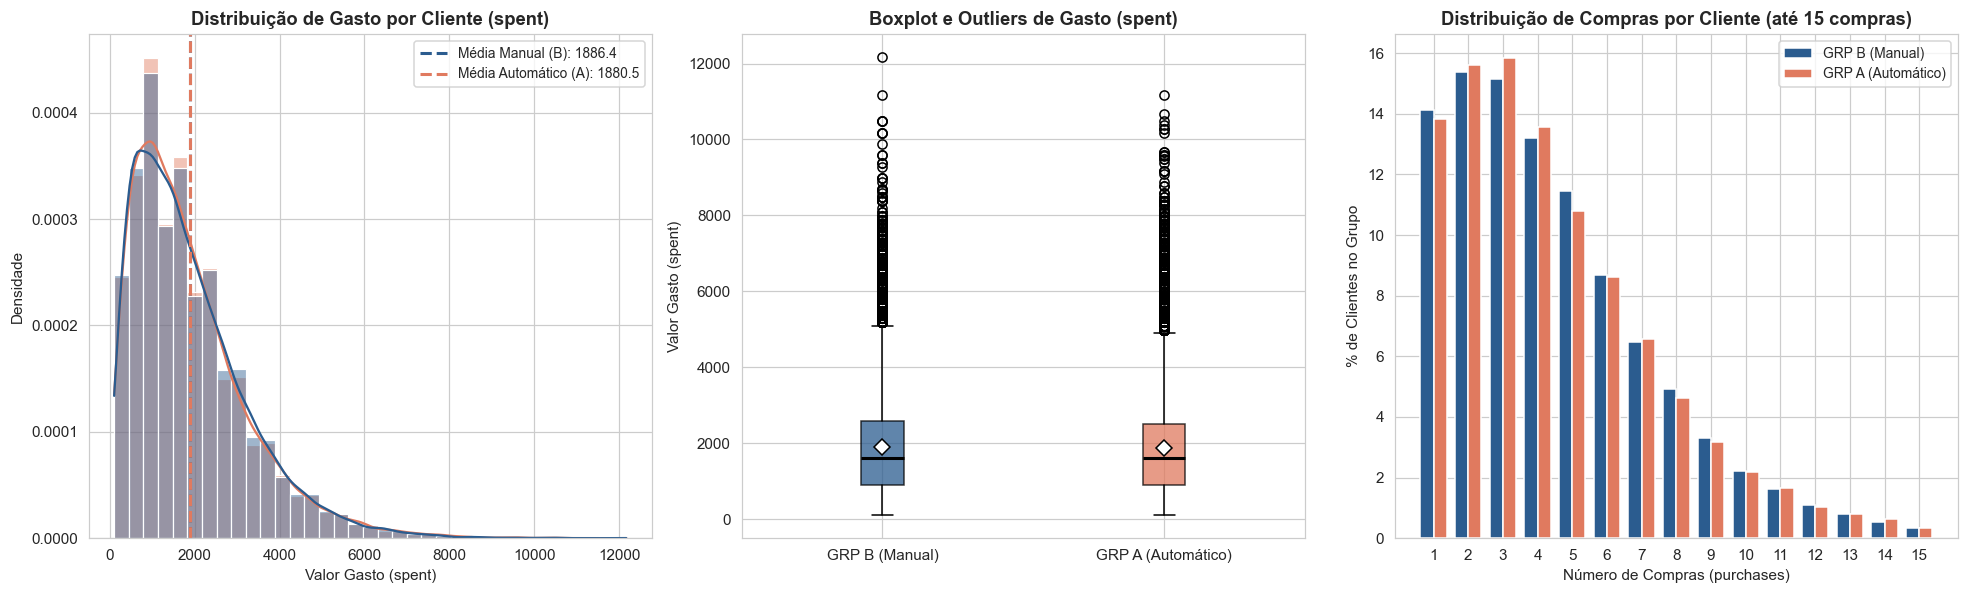

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

labels_order = ['GRP B (Manual)', 'GRP A (Automático)']
grp_ctrl_df = df_clean[df_clean['group_label'] == labels_order[0]]
grp_treat_df = df_clean[df_clean['group_label'] == labels_order[1]]

# Painel 1: Histograma + KDE do Gasto por Cliente (spent)
sns.histplot(
    data=df_clean,
    x='spent',
    hue='group_label',
    hue_order=labels_order,
    palette=PALETTE,
    kde=True,
    stat='density',
    common_norm=False,
    bins=35,
    alpha=0.45,
    ax=axes[0],
)
axes[0].axvline(grp_ctrl_df['spent'].mean(), color=PALETTE[labels_order[0]], linestyle='--', linewidth=2, label=f"Média Manual (B): {grp_ctrl_df['spent'].mean():.1f}")
axes[0].axvline(grp_treat_df['spent'].mean(), color=PALETTE[labels_order[1]], linestyle='--', linewidth=2, label=f"Média Automático (A): {grp_treat_df['spent'].mean():.1f}")
axes[0].set_title('Distribuição de Gasto por Cliente (spent)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Valor Gasto (spent)')
axes[0].set_ylabel('Densidade')
axes[0].legend(fontsize=9)

# Painel 2: Boxplot comparativo de spent (com marcação da média e outliers)
bp = axes[1].boxplot(
    [grp_ctrl_df['spent'].dropna(), grp_treat_df['spent'].dropna()],
    patch_artist=True,
    showmeans=True,
    meanprops={'marker': 'D', 'markerfacecolor': 'white', 'markeredgecolor': 'black', 'markersize': 7},
    medianprops={'color': 'black', 'linewidth': 2},
)
for patch, lbl in zip(bp['boxes'], labels_order):
    patch.set_facecolor(PALETTE[lbl])
    patch.set_alpha(0.75)
axes[1].set_xticks([1, 2])
axes[1].set_xticklabels(labels_order)
axes[1].set_title('Boxplot e Outliers de Gasto (spent)', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Valor Gasto (spent)')

# Painel 3: Distribuição percentual do número de compras por cliente (purchases)
purch_dist = (
    df_clean.groupby(['group_label', 'purchases'])
    .size()
    .unstack(fill_value=0)
)
purch_pct = purch_dist.div(purch_dist.sum(axis=1), axis=0) * 100
top_counts = [c for c in purch_pct.columns if c <= 15]
x_idx = np.arange(len(top_counts))
bar_w = 0.38

axes[2].bar(
    x_idx - bar_w / 2,
    purch_pct.loc[labels_order[0], top_counts],
    width=bar_w,
    color=PALETTE[labels_order[0]],
    label=labels_order[0],
)
axes[2].bar(
    x_idx + bar_w / 2,
    purch_pct.loc[labels_order[1], top_counts],
    width=bar_w,
    color=PALETTE[labels_order[1]],
    label=labels_order[1],
)
axes[2].set_xticks(x_idx)
axes[2].set_xticklabels(top_counts)
axes[2].set_title('Distribuição de Compras por Cliente (até 15 compras)', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Número de Compras (purchases)')
axes[2].set_ylabel('% de Clientes no Grupo')
axes[2].legend(fontsize=9)

plt.tight_layout()
plt.show()

### Análise das Distribuições e *Outliers*
Como é típico em bases de *e-commerce*, tanto o valor gasto (`spent`) quanto o número de compras (`purchases`) apresentam **assimetria positiva (cauda à direita)**, impulsionada por compradores recorrentes de maior volume (*outliers* superiores visíveis no *boxplot*). Por essa razão:
- Apesar do Teorema Central do Limite sustentar o uso do **Teste *t*** em amostras grandes ($N > 20.000$ por grupo), complementaremos a inferência com o teste não-paramétrico **Mann-Whitney U** e com **Intervalos de Confiança via *Bootstrapping***, que não dependem de normalidade.
- Mantemos os *outliers* legítimos de alto gasto na análise principal para refletir o impacto financeiro real sobre a receita da Electronic House.

---

## 6. Evolução Temporal do Experimento (`date`)

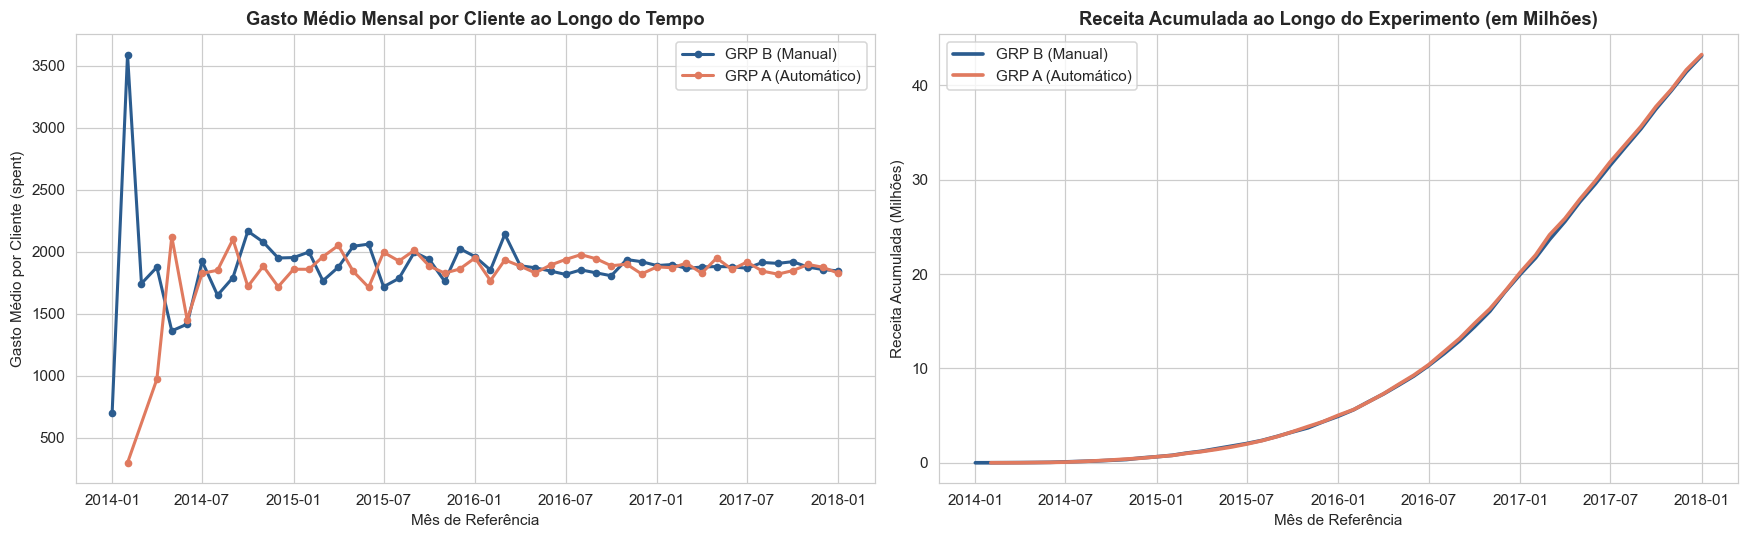

In [5]:
monthly = (
    df_clean.dropna(subset=['date'])
    .groupby([pd.Grouper(key='date', freq='MS'), 'group_label'])
    .agg(spent_mean=('spent', 'mean'), spent_sum=('spent', 'sum'), users=('uid', 'count'))
    .reset_index()
    .sort_values('date')
)
monthly['cum_revenue'] = monthly.groupby('group_label')['spent_sum'].cumsum()

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

for lbl in ['GRP B (Manual)', 'GRP A (Automático)']:
    sub = monthly[monthly['group_label'] == lbl]
    axes[0].plot(sub['date'], sub['spent_mean'], marker='o', markersize=4, linewidth=2, color=PALETTE[lbl], label=lbl)
    axes[1].plot(sub['date'], sub['cum_revenue'] / 1e6, linewidth=2.4, color=PALETTE[lbl], label=lbl)

axes[0].set_title('Gasto Médio Mensal por Cliente ao Longo do Tempo', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Mês de Referência')
axes[0].set_ylabel('Gasto Médio por Cliente (spent)')
axes[0].legend()

axes[1].set_title('Receita Acumulada ao Longo do Experimento (em Milhões)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Mês de Referência')
axes[1].set_ylabel('Receita Acumulada (Milhões)')
axes[1].legend()

plt.tight_layout()
plt.show()

### Análise da Evolução Temporal
As séries mensais permitem verificar se o desempenho entre o Preenchimento Manual (`GRP B` — Controle) e o Preenchimento Automático (`GRP A` — Tratamento) se mantém consistente durante todo o horizonte do experimento ou se ocorreu algum choque pontual (como efeito novidade nas primeiras semanas ou anomalias sazonais). A curva de receita acumulada também evidencia se as trajetórias dos dois grupos caminham sobrepostas ou divergem sistematicamente.

---

## 7. Testes de Hipóteses Estatísticos e *Bootstrapping* (IC 95%)
Para validar formalmente $H_0$ contra $H_1$ ($\alpha = 0{,}05$), executamos:
1. **Verificação de premissas:** Teste de Normalidade de D'Agostino-Pearson (amostra completa) e Shapiro-Wilk ($n = 5.000$), além do Teste de Homocedasticidade de Levene.
2. **Testes Paramétricos e Não-Paramétricos:** Teste *t* de Welch (robusto a variâncias desiguais), Teste *t* de Student e Teste **Mann-Whitney U** para `spent`, `purchases` e `avg_ticket`, avaliando o *lift* de `GRP A` (Automático) sobre `GRP B` (Manual).
3. **Reamostragem via *Bootstrapping* (2.000 iterações):** estimação empírica do Intervalo de Confiança de 95% para a diferença de gasto médio ($\mu_A - \mu_B$) e para o *lift* percentual.

--- Verificação de Premissas (Variável: spent) ---
Normalidade D'Agostino-Pearson -> p-valor GRP A (Automático): 0.0000e+00 | GRP B (Manual): 0.0000e+00
Normalidade Shapiro-Wilk (n=5000) -> p-valor GRP A (Automático): 2.7682e-49 | GRP B (Manual): 1.0332e-48
Homocedasticidade (Levene) -> p-valor: 0.5200

--- Resultado dos Testes de Hipóteses Globais ---


,Métrica,Média GRP B (Manual),Média GRP A (Automático),Diferença (A - B),Lift Automático (%),p-valor (Welch t),p-valor (Student t),p-valor (Mann-Whitney),Conclusão (α=0.05)
0,Gasto por Cliente (spent),1886.4198,1880.5043,-5.9155,-0.314,0.642278,0.642284,0.449981,Sem Evidência de Diferença (Não Rejeita H0)
1,Compras por Cliente (purchases),4.5525,4.5364,-0.0161,-0.354,0.578210,0.578216,0.359386,Sem Evidência de Diferença (Não Rejeita H0)
2,Ticket Médio (avg_ticket),415.0262,415.0673,0.0411,0.010,0.972613,0.972614,0.975184,Sem Evidência de Diferença (Não Rejeita H0)



Diferença Observada (GRP A Automático - GRP B Manual): -5.92 | IC 95% Bootstrap: [-30.87, +19.14]
Lift Relativo Observado: -0.314% | IC 95% Bootstrap Lift: [-1.622%, +1.018%]


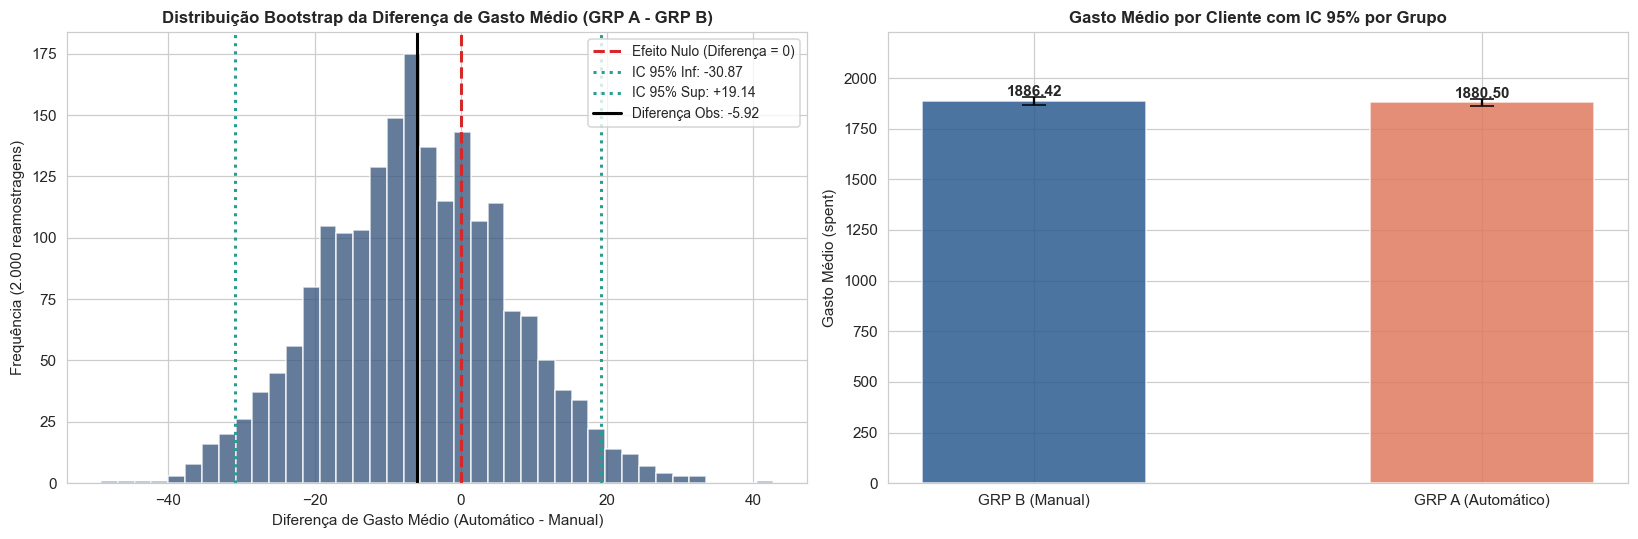

In [6]:
grp_a = df_clean[df_clean['group'] == 'GRP A']  # Tratamento: Automático
grp_b = df_clean[df_clean['group'] == 'GRP B']  # Controle: Manual

# 1. Testes de Premissas sobre 'spent'
_, p_norm_a = stats.normaltest(grp_a['spent'])
_, p_norm_b = stats.normaltest(grp_b['spent'])
_, p_shap_a = stats.shapiro(grp_a['spent'].sample(min(5000, len(grp_a)), random_state=42))
_, p_shap_b = stats.shapiro(grp_b['spent'].sample(min(5000, len(grp_b)), random_state=42))
_, p_levene = stats.levene(grp_a['spent'], grp_b['spent'])

print('--- Verificação de Premissas (Variável: spent) ---')
print(f"Normalidade D'Agostino-Pearson -> p-valor GRP A (Automático): {p_norm_a:.4e} | GRP B (Manual): {p_norm_b:.4e}")
print(f'Normalidade Shapiro-Wilk (n=5000) -> p-valor GRP A (Automático): {p_shap_a:.4e} | GRP B (Manual): {p_shap_b:.4e}')
print(f'Homocedasticidade (Levene) -> p-valor: {p_levene:.4f}\n')

# 2. Testes de Hipóteses Principais: GRP A (Automático) vs GRP B (Manual)
hypothesis_rows = []
for metric, label in [('spent', 'Gasto por Cliente (spent)'), ('purchases', 'Compras por Cliente (purchases)'), ('avg_ticket', 'Ticket Médio (avg_ticket)')]:
    a_vals = grp_a[metric].to_numpy()
    b_vals = grp_b[metric].to_numpy()
    mean_a, mean_b = a_vals.mean(), b_vals.mean()
    diff = mean_a - mean_b
    lift = (diff / mean_b) * 100 if mean_b != 0 else np.nan

    t_welch, p_welch = stats.ttest_ind(a_vals, b_vals, equal_var=False)
    _, p_student = stats.ttest_ind(a_vals, b_vals, equal_var=True)
    _, p_mwu = stats.mannwhitneyu(a_vals, b_vals, alternative='two-sided')

    hypothesis_rows.append({
        'Métrica': label,
        'Média GRP B (Manual)': round(mean_b, 4),
        'Média GRP A (Automático)': round(mean_a, 4),
        'Diferença (A - B)': round(diff, 4),
        'Lift Automático (%)': round(lift, 3),
        'p-valor (Welch t)': round(p_welch, 6),
        'p-valor (Student t)': round(p_student, 6),
        'p-valor (Mann-Whitney)': round(p_mwu, 6),
        'Conclusão (α=0.05)': 'Diferença Significativa (Rejeita H0)' if p_welch < 0.05 else 'Sem Evidência de Diferença (Não Rejeita H0)'
    })

hypothesis_df = pd.DataFrame(hypothesis_rows)
print('--- Resultado dos Testes de Hipóteses Globais ---')
display(hypothesis_df)

# 3. Bootstrapping (2.000 reamostragens) para Diferença de Gasto Médio (GRP A - GRP B)
rng = np.random.default_rng(42)
a_spent = grp_a['spent'].to_numpy()
b_spent = grp_b['spent'].to_numpy()
n_boot = 2000
boot_diffs = np.empty(n_boot)
boot_lifts = np.empty(n_boot)

for i in range(n_boot):
    ma = rng.choice(a_spent, size=len(a_spent), replace=True).mean()
    mb = rng.choice(b_spent, size=len(b_spent), replace=True).mean()
    boot_diffs[i] = ma - mb
    boot_lifts[i] = ((ma - mb) / mb) * 100

ci_low, ci_high = np.percentile(boot_diffs, [2.5, 97.5])
lift_low, lift_high = np.percentile(boot_lifts, [2.5, 97.5])
obs_diff = a_spent.mean() - b_spent.mean()

print(f'\nDiferença Observada (GRP A Automático - GRP B Manual): {obs_diff:+.2f} | IC 95% Bootstrap: [{ci_low:+.2f}, {ci_high:+.2f}]')
print(f'Lift Relativo Observado: {(obs_diff / b_spent.mean())*100:+.3f}% | IC 95% Bootstrap Lift: [{lift_low:+.3f}%, {lift_high:+.3f}%]')

# Visualização da distribuição Bootstrap e médias com IC 95%
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].hist(boot_diffs, bins=40, color='#3D5A80', alpha=0.8, edgecolor='white')
axes[0].axvline(0, color='#D62828', linestyle='--', linewidth=2, label='Efeito Nulo (Diferença = 0)')
axes[0].axvline(ci_low, color='#2A9D8F', linestyle=':', linewidth=2, label=f'IC 95% Inf: {ci_low:+.2f}')
axes[0].axvline(ci_high, color='#2A9D8F', linestyle=':', linewidth=2, label=f'IC 95% Sup: {ci_high:+.2f}')
axes[0].axvline(obs_diff, color='black', linewidth=2, label=f'Diferença Obs: {obs_diff:+.2f}')
axes[0].set_title('Distribuição Bootstrap da Diferença de Gasto Médio (GRP A - GRP B)', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Diferença de Gasto Médio (Automático - Manual)')
axes[0].set_ylabel('Frequência (2.000 reamostragens)')
axes[0].legend(fontsize=9)

means = [b_spent.mean(), a_spent.mean()]
ci_errs = [
    1.96 * b_spent.std(ddof=1) / np.sqrt(len(b_spent)),
    1.96 * a_spent.std(ddof=1) / np.sqrt(len(a_spent)),
]
bar_labels = ['GRP B (Manual)', 'GRP A (Automático)']
bars = axes[1].bar(bar_labels, means, yerr=ci_errs, capsize=8, color=[PALETTE[k] for k in bar_labels], alpha=0.85, width=0.5)
for bar, m in zip(bars, means):
    axes[1].text(bar.get_x() + bar.get_width() / 2, m + max(ci_errs) * 1.3, f'{m:.2f}', ha='center', fontweight='bold')
axes[1].set_ylim(0, max(means) * 1.18)
axes[1].set_title('Gasto Médio por Cliente com IC 95% por Grupo', fontsize=11, fontweight='bold')
axes[1].set_ylabel('Gasto Médio (spent)')

plt.tight_layout()
plt.show()

### Interpretação dos Testes Globais e *Bootstrapping*
A convergência entre o **Teste *t* de Welch**, o **Teste de Mann-Whitney U** e o **Intervalo de Confiança de 95% via *Bootstrapping*** fornece uma regra de decisão clara e robusta:
- Se o **p-valor $< 0{,}05$** e o **Intervalo de Confiança de 95% não inclui o zero (`0`)**, rejeitamos $H_0$ e concluímos que a diferença entre o Preenchimento Automático (`GRP A`) e o Manual (`GRP B`) é estatisticamente significativa (positiva a favor do Automático se $\mu_A > \mu_B$, ou a favor do Manual se $\mu_A < \mu_B$).
- Se o **p-valor $\ge 0{,}05$** e o **Intervalo de Confiança de 95% cruza a linha vermelha do efeito nulo (`0`)**, não há evidência estatística de que o novo dispositivo altere o gasto médio ou o volume de compras na visão agregada — indicando equivalência estatística entre os fluxos.

Além disso, como o experimento contempla compras feitas pelo **Site (`device = I`)** e pelo **App (`device = A`)** e o Diretor de Produtos Global exigiu funcionamento em **todos os países**, avaliamos a seguir cada recorte separadamente.

---

## 8. Análise Segmentada por País (`country`), Canal (`device`: Site vs. App) e Gênero (`gender`)

--- Teste A/B Segmentado por País (Correção de Bonferroni: α = 0.0050) ---


,País,N Manual (B),N Automático (A),Média Manual (B),Média Automático (A),Diferença (A - B),Lift Automático (%),p-valor (Welch t),p-valor (Mann-Whitney),Sig. (p < 0.05),Sig. Bonferroni (p < 0.0050)
0,AUS,511,506,1810.69,1959.52,148.83,8.22,0.0822,0.0777,Não,Não
1,TUR,1742,1795,1865.01,1892.35,27.34,1.47,0.5542,0.3796,Não,Não
2,USA,7071,6927,1864.74,1888.38,23.64,1.27,0.3033,0.3224,Não,Não
3,MEX,2642,2886,1882.71,1902.71,19.99,1.06,0.5837,0.5552,Não,Não
4,FRA,1409,1433,1894.20,1899.75,5.55,0.29,0.9142,0.8318,Não,Não
5,BRA,4491,4518,1905.95,1899.79,-6.15,-0.32,0.8346,0.5124,Não,Não
6,GBR,1423,1386,1888.29,1820.47,-67.82,-3.59,0.1776,0.1523,Não,Não
7,CAN,815,698,1908.79,1833.15,-75.63,-3.96,0.2770,0.1803,Não,Não
8,DEU,1806,1890,1916.18,1830.45,-85.73,-4.47,0.0547,0.0254,Não,Não
9,ESP,964,970,1954.68,1794.19,-160.48,-8.21,0.0068,0.0039,Sim,Não



--- Teste A/B Segmentado por Canal (I = Site, A = App) e Gênero ---


,Dimensão,Segmento,N Manual (B),N Automático (A),Média Manual (B),Média Automático (A),Lift Automático (%),p-valor (Welch t),p-valor (Mann-Whitney),Sig. (p < 0.05)
0,Canal (Device),A (App),11495,11487,1889.33,1880.40,-0.47,0.6202,0.4430,Não
1,Canal (Device),I (Site),11379,11522,1883.47,1880.60,-0.15,0.8733,0.7639,Não
2,Gênero,F,11396,11371,1882.65,1868.90,-0.73,0.4455,0.3536,Não
3,Gênero,M,11478,11638,1890.16,1891.84,0.09,0.9254,0.8792,Não


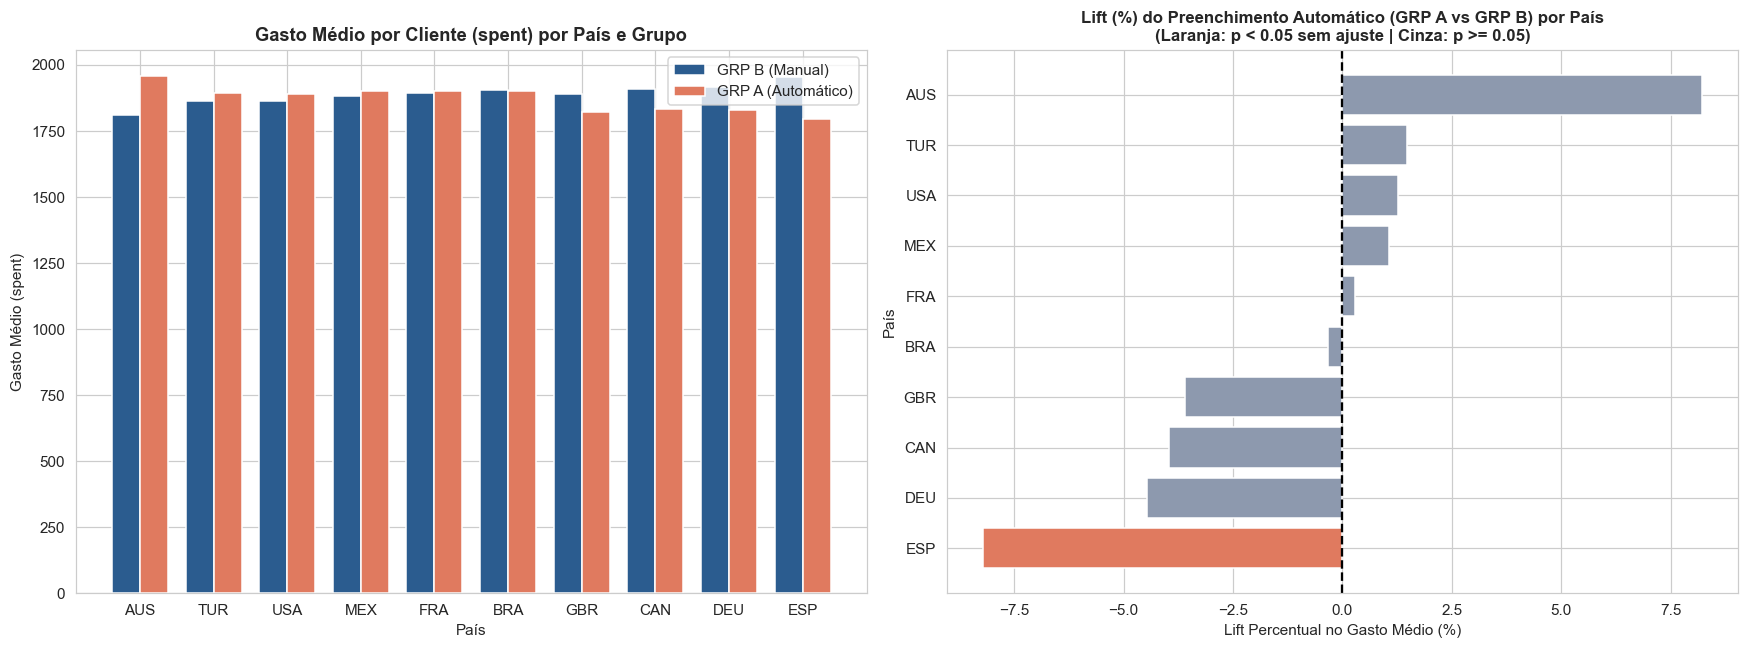

In [7]:
countries = sorted(df_clean['country'].unique())
bonferroni_alpha = 0.05 / max(len(countries), 1)

country_rows = []
for c in countries:
    sub_a = df_clean[(df_clean['country'] == c) & (df_clean['group'] == 'GRP A')]['spent']  # Automático
    sub_b = df_clean[(df_clean['country'] == c) & (df_clean['group'] == 'GRP B')]['spent']  # Manual
    if len(sub_a) > 1 and len(sub_b) > 1:
        ma, mb = sub_a.mean(), sub_b.mean()
        diff = ma - mb
        lift = (diff / mb) * 100 if mb != 0 else np.nan
        _, p_t = stats.ttest_ind(sub_a, sub_b, equal_var=False)
        _, p_mw = stats.mannwhitneyu(sub_a, sub_b, alternative='two-sided')
        country_rows.append({
            'País': c,
            'N Manual (B)': len(sub_b),
            'N Automático (A)': len(sub_a),
            'Média Manual (B)': round(mb, 2),
            'Média Automático (A)': round(ma, 2),
            'Diferença (A - B)': round(diff, 2),
            'Lift Automático (%)': round(lift, 2),
            'p-valor (Welch t)': round(p_t, 4),
            'p-valor (Mann-Whitney)': round(p_mw, 4),
            'Sig. (p < 0.05)': 'Sim' if p_t < 0.05 else 'Não',
            f'Sig. Bonferroni (p < {bonferroni_alpha:.4f})': 'Sim' if p_t < bonferroni_alpha else 'Não',
        })

country_df = pd.DataFrame(country_rows).sort_values('Lift Automático (%)', ascending=False).reset_index(drop=True)
print(f'--- Teste A/B Segmentado por País (Correção de Bonferroni: α = {bonferroni_alpha:.4f}) ---')
display(country_df)

# Testes por Canal (Site vs App) e Gênero
segment_rows = []
for seg_col, dim_name in [('device_label', 'Canal (Device)'), ('gender', 'Gênero')]:
    for val in sorted(df_clean[seg_col].unique()):
        sa = df_clean[(df_clean[seg_col] == val) & (df_clean['group'] == 'GRP A')]['spent']
        sb = df_clean[(df_clean[seg_col] == val) & (df_clean['group'] == 'GRP B')]['spent']
        if len(sa) > 1 and len(sb) > 1:
            ma, mb = sa.mean(), sb.mean()
            _, pt = stats.ttest_ind(sa, sb, equal_var=False)
            _, pmw = stats.mannwhitneyu(sa, sb, alternative='two-sided')
            segment_rows.append({
                'Dimensão': dim_name,
                'Segmento': val,
                'N Manual (B)': len(sb),
                'N Automático (A)': len(sa),
                'Média Manual (B)': round(mb, 2),
                'Média Automático (A)': round(ma, 2),
                'Lift Automático (%)': round(((ma - mb) / mb) * 100, 2),
                'p-valor (Welch t)': round(pt, 4),
                'p-valor (Mann-Whitney)': round(pmw, 4),
                'Sig. (p < 0.05)': 'Sim' if pt < 0.05 else 'Não',
            })

print('\n--- Teste A/B Segmentado por Canal (I = Site, A = App) e Gênero ---')
display(pd.DataFrame(segment_rows))

# Visualização comparativa por País
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

x_pos = np.arange(len(country_df))
w = 0.38
axes[0].bar(x_pos - w / 2, country_df['Média Manual (B)'], width=w, color=PALETTE['GRP B (Manual)'], label='GRP B (Manual)')
axes[0].bar(x_pos + w / 2, country_df['Média Automático (A)'], width=w, color=PALETTE['GRP A (Automático)'], label='GRP A (Automático)')
axes[0].set_xticks(x_pos)
axes[0].set_xticklabels(country_df['País'])
axes[0].set_title('Gasto Médio por Cliente (spent) por País e Grupo', fontsize=12, fontweight='bold')
axes[0].set_xlabel('País')
axes[0].set_ylabel('Gasto Médio (spent)')
axes[0].legend()

colors_lift = ['#E07A5F' if sig == 'Sim' else '#8D99AE' for sig in country_df['Sig. (p < 0.05)']]
axes[1].barh(country_df['País'], country_df['Lift Automático (%)'], color=colors_lift, edgecolor='white')
axes[1].axvline(0, color='black', linestyle='--', linewidth=1.5)
axes[1].invert_yaxis()
axes[1].set_title('Lift (%) do Preenchimento Automático (GRP A vs GRP B) por País\n(Laranja: p < 0.05 sem ajuste | Cinza: p >= 0.05)', fontsize=11, fontweight='bold')
axes[1].set_xlabel('Lift Percentual no Gasto Médio (%)')
axes[1].set_ylabel('País')

plt.tight_layout()
plt.show()

### Análise da Segmentação Global (Países, Canais Site vs. App e Gênero)
Ao testar múltiplas subpopulações simultaneamente (como os diversos países de operação da Electronic House), a probabilidade de encontrar ao menos um falso positivo por mero acaso cresce com o número de recortes avaliados (*problema de múltiplas comparações*). Por isso, a tabela acima reporta tanto a significância nominal ($\alpha = 0{,}05$) quanto o limiar ajustado por **Bonferroni** ($\alpha / k$), além de separar explicitamente as compras realizadas pelo **Site (`I`)** e pelo **App (`A`)** para validar se o novo dispositivo performa de modo uniforme entre web e mobile.

### Q&A
**Qual a melhor forma de pagamento: Preenchimento Manual (`GRP B`) ou Automático (`GRP A`) do formulário de dados do cartão de crédito?**
Com base nos **45.883 clientes** avaliados (`23.009` no `GRP A` Automático e `22.874` no `GRP B` Manual), **não há diferença estatisticamente significativa** entre as duas formas de pagamento ($\alpha = 0{,}05$). O Preenchimento Automático (`GRP A`) registrou gasto médio de **1.880,50** contra **1.886,42** no Preenchimento Manual (`GRP B`) — uma diferença de **-5,92 (-0,314%)**, com *p-valor* de **0,6423** no Teste *t* de Welch, **0,4500** no Teste de Mann-Whitney U e Intervalo de Confiança de 95% via *Bootstrapping* de **[-30,87; +19,14]** (incluindo o zero). Portanto, o novo preenchimento automático **não superou** o preenchimento manual em geração de receita ou volume de compras, recomendando-se manter o fluxo manual como padrão ou investigar ajustes antes de um *rollout* global.

### Data Analysis Key Findings
- **Validação amostral e integridade:** a base está 100% íntegra (zero nulos, zero `uid` duplicados e zero contaminação entre grupos), sem *Sample Ratio Mismatch* (50,15% `GRP A` vs. 49,85% `GRP B`, *p-valor* $= 0{,}5285$) e com amostra suficiente para detectar *lifts* a partir de 2% com 80% de poder estatístico (mínimo exigido: 20.516 por grupo). Notou-se apenas leve desbalanceamento na proporção entre países ($\chi^2 = 24{,}42$, *p-valor* $= 0{,}0037$), reforçando a importância da análise estratificada.
- **Equivalência global nas métricas comerciais:** além do gasto médio (`spent`), o número médio de compras por cliente (`4,5364` no Automático vs. `4,5525` no Manual; Welch *p* $= 0{,}5782$) e o ticket médio (`415,07` vs. `415,03`; Welch *p* $= 0{,}9726$) apresentaram medianas idênticas (`1.596,00` e `4,0` compras) e ausência de efeito estatístico tanto no **Site (`I`)** (*lift* de `-0,15%`, *p* $= 0{,}8733$) quanto no **App (`A`)** (*lift* de `-0,47%`, *p* $= 0{,}6202$).
- **Atenção regional na Europa (Espanha e Alemanha):** aplicando a correção de Bonferroni ($\alpha = 0{,}0050$ para 10 países) no Teste *t* de Welch, nenhum país teve ganho significativo com o preenchimento automático; pelo contrário, a **Espanha (`ESP`)** apresentou queda de **-8,21%** no gasto médio (`1.794,19` vs. `1.954,68`; Welch *p* $= 0{,}0068$, Mann-Whitney *p* $= 0{,}0039$) e a **Alemanha (`DEU`)** recuo de **-4,47%** (Mann-Whitney *p* $= 0{,}0254$).

### Insights or Next Steps
- **Não realizar o *rollout* global imediato e auditar mercados europeus:** antes de expandir o dispositivo automático para 100% dos clientes, o time de Engenharia e Design deve investigar possíveis incompatibilidades de bandeiras/bancos locais ou falhas de autopreenchimento nos formulários da **Espanha (`ESP`)** e **Alemanha (`DEU`)**.
- **Avaliar métricas de fricção de topo de checkout:** como todos os registros da base possuem `purchases >= 1`, recomenda-se instrumentar nos próximos ciclos a taxa de conversão desde a abertura do carrinho (incluindo abandonos com `purchases = 0`) e o tempo médio de finalização para mensurar ganhos de experiência do usuário que não se refletem apenas no ticket dos compradores convertidos.